# PC3 – PCA of the movie data (MovieLens)

**Goal:** apply PCA to movie ratings, decide how many dimensions are needed and try to interpret the result with a biplot.

**Data:** MovieLens `ml-latest-small` (GroupLens research group, folder `../ml-latest-small/`). It contains about 100 000 ratings
of 9 700 movies by 610 users. We use `ratings.csv` (who rated which movie how) and `movies.csv` (titles and genres).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

ratings = pd.read_csv("../ml-latest-small/ratings.csv")
movies = pd.read_csv("../ml-latest-small/movies.csv").set_index("movieId")
print(ratings.shape)
ratings.head()

(100836, 4)


,userId,movieId,rating,timestamp
0,1,1,4.0,964982703
1,1,3,4.0,964981247
2,1,6,4.0,964982224
3,1,47,5.0,964983815
4,1,50,5.0,964982931


In [2]:
movies.head()

,title,genres
movieId,,
1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
2,Jumanji (1995),Adventure|Children|Fantasy
3,Grumpier Old Men (1995),Comedy|Romance
4,Waiting to Exhale (1995),Comedy|Drama|Romance
5,Father of the Bride Part II (1995),Comedy


## (a) Data understanding

`ratings.csv` is in **long format**: one row per rating with the columns `userId`, `movieId`, `rating` (0.5 – 5 stars, steps of
0.5) and `timestamp`. For a PCA we need a data matrix *X* with one row per observation and one column per variable. The natural
choice is the **user × movie rating matrix**:
- **rows = users** (observations),
- **columns = movies** (variables),
- **entry = rating** of this user for this movie, or *missing* if the user has not rated the movie.

In [3]:
R = ratings.pivot(index="userId", columns="movieId", values="rating")
print("rating matrix:", R.shape, "(users x movies)")
n_known = R.notna().sum().sum()
print(f"known ratings : {n_known:,} of {R.size:,} cells = {n_known / R.size:.1%}")
print(f"missing       : {1 - n_known / R.size:.1%}")
R.iloc[:5, :8].rename(columns=movies["title"])

rating matrix: (610, 9724) (users x movies)


known ratings : 100,836 of 5,931,640 cells = 1.7%
missing       : 98.3%


movieId,Toy Story (1995),Jumanji (1995),Grumpier Old Men (1995),Waiting to Exhale (1995),Father of the Bride Part II (1995),Heat (1995),Sabrina (1995),Tom and Huck (1995)
userId,,,,,,,,
1,4.0,NaN,4.0,NaN,NaN,4.0,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,4.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN


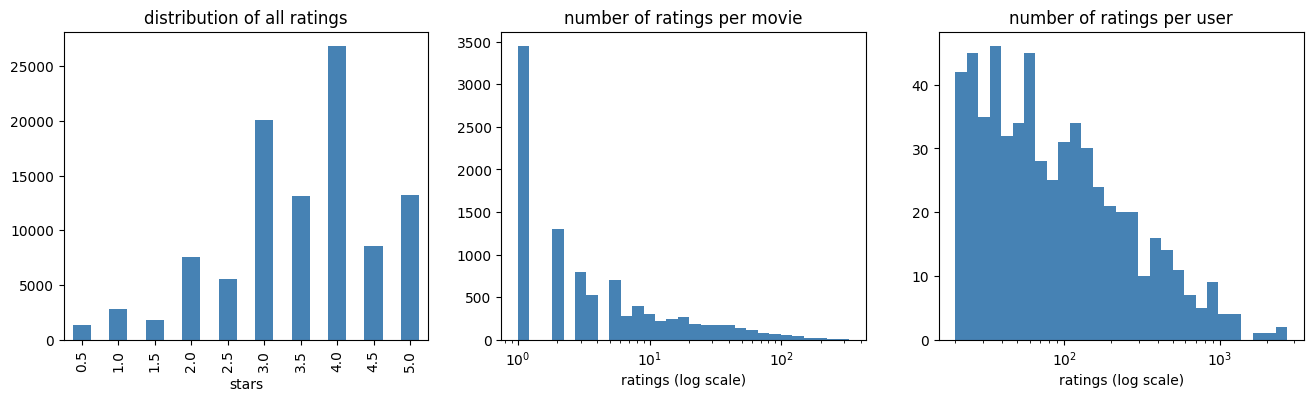

ratings per movie: median 3.0 | movies with only 1 rating: 3446
ratings per user : min 20 | median 70.5 | max 2698


mean rating per user ranges from 1.27 to 5.00


In [4]:
per_movie = R.notna().sum()
per_user = R.notna().sum(axis=1)

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ratings["rating"].value_counts().sort_index().plot(kind="bar", ax=ax[0], color="steelblue")
ax[0].set_title("distribution of all ratings"); ax[0].set_xlabel("stars")
ax[1].hist(per_movie, bins=np.logspace(0, np.log10(per_movie.max()), 30), color="steelblue")
ax[1].set_xscale("log"); ax[1].set_title("number of ratings per movie"); ax[1].set_xlabel("ratings (log scale)")
ax[2].hist(per_user, bins=np.logspace(np.log10(20), np.log10(per_user.max()), 30), color="steelblue")
ax[2].set_xscale("log"); ax[2].set_title("number of ratings per user"); ax[2].set_xlabel("ratings (log scale)")
plt.show()

print("ratings per movie: median", per_movie.median(), "| movies with only 1 rating:", (per_movie == 1).sum())
print("ratings per user : min", per_user.min(), "| median", per_user.median(), "| max", per_user.max())
user_mean = R.mean(axis=1)
print(f"mean rating per user ranges from {user_mean.min():.2f} to {user_mean.max():.2f}")

**What do we have?**
- **610 rows (users) × 9 724 columns (movies)**. There are many more variables than observations (*p* ≫ *n*).
- **Entries:** ratings from 0.5 to 5 stars (most common: 4 and 3). All variables have the **same meaning and the same scale**.
- The matrix is **extremely sparse: 98.3 % of the entries are missing**. Half of the movies have 3 ratings or fewer
  (about 3 400 movies have only a single rating), while a few popular movies have more than 300.
- Users differ a lot: some rated only 20 movies, one rated 2 698. Some users are generous, others are strict
  (see the range of the mean rating per user above).

**Should we normalize?**
- **No standardization of the columns (z-scores).** Like for MNIST, all variables are ratings on the same 0.5 – 5 scale.
  Standardizing would even be harmful: a movie with only 2 ratings has an almost random, often tiny standard deviation, and
  dividing by it would give this movie a huge weight.
- **But we must deal with the missing values** – this is the real preprocessing question here. PCA needs a full matrix.
  Filling with 0 would mean "the user hated the movie" (0 stars is even below the minimum of the scale), which is wrong.
- Our choice: **center each user by their own mean rating** and then fill the missing entries with **0**. After centering,
  a value means "better (+) or worse (−) than this user usually rates", and a missing value is treated as "average for this user".
  This also removes the difference between generous and strict raters, which is not interesting for the movie structure.
  (PCA then centers every column again, as always.)

In [5]:
R_centered = R.sub(user_mean, axis=0)       # rating - user mean
X = R_centered.fillna(0).values              # missing = "average for this user"
print(X.shape, "| mean of X:", X.mean().round(4))

(610, 9724) | mean of X: 0.0


## (b) Apply PCA – how many dimensions do we need?

Important detail: the matrix has only *n* = 610 rows. After centering, the data lie in a space of at most *n* − 1 = 609
dimensions, so PCA can find at most **609 components with non-zero variance** – even though there are 9 724 variables.

In [6]:
pca = PCA()
scores = pca.fit_transform(X)
ratio = pca.explained_variance_ratio_
cum = np.cumsum(ratio)

print("number of components:", len(ratio))
print("explained variance of the first 10 PCs:", ratio[:10].round(3))
print(f"PC1 + PC2 together explain: {cum[1]:.1%}\n")
for t in [0.5, 0.8, 0.9, 0.95]:
    print(f"{t:.0%} of the variance needs {np.argmax(cum >= t) + 1:4d} components")

number of components: 610
explained variance of the first 10 PCs: [0.054 0.022 0.019 0.018 0.016 0.015 0.014 0.014 0.013 0.013]
PC1 + PC2 together explain: 7.6%

50% of the variance needs   52 components
80% of the variance needs  163 components
90% of the variance needs  252 components
95% of the variance needs  335 components


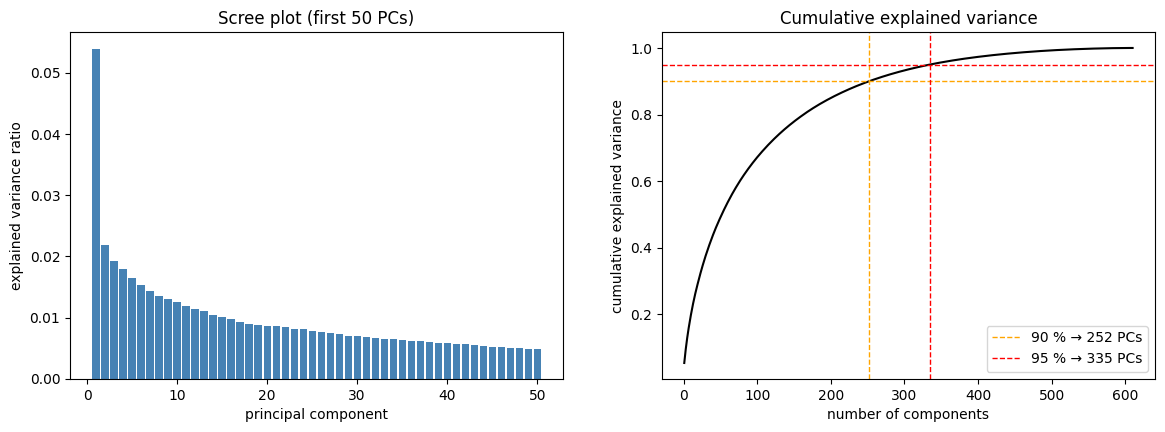

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].bar(np.arange(1, 51), ratio[:50], color="steelblue")
ax[0].set_xlabel("principal component"); ax[0].set_ylabel("explained variance ratio")
ax[0].set_title("Scree plot (first 50 PCs)")

ax[1].plot(np.arange(1, len(cum) + 1), cum, "k-")
for t, c in [(0.9, "orange"), (0.95, "red")]:
    k = np.argmax(cum >= t) + 1
    ax[1].axhline(t, color=c, ls="--", lw=1)
    ax[1].axvline(k, color=c, ls="--", lw=1, label=f"{int(t*100)} % → {k} PCs")
ax[1].set_xlabel("number of components"); ax[1].set_ylabel("cumulative explained variance")
ax[1].set_title("Cumulative explained variance"); ax[1].legend()
plt.show()

Most movies have only a few ratings and are almost only "0" (missing) in our matrix – they mainly add noise. As a robustness check we
repeat the PCA with only the **450 movies that have at least 50 ratings**:

In [8]:
popular = per_movie[per_movie >= 50].index
R_pop = R[popular]
X_pop = R_pop.sub(R_pop.mean(axis=1), axis=0).fillna(0).values
titles_pop = movies.loc[popular, "title"].values

pca_pop = PCA()
scores_pop = pca_pop.fit_transform(X_pop)
ratio_pop = pca_pop.explained_variance_ratio_
cum_pop = np.cumsum(ratio_pop)
print("matrix:", X_pop.shape, f"| missing: {R_pop.isna().mean().mean():.1%}")
print("explained variance of the first 5 PCs:", ratio_pop[:5].round(3))
print(f"PC1 + PC2 together explain: {cum_pop[1]:.1%}")
for t in [0.5, 0.8, 0.9, 0.95]:
    print(f"{t:.0%} of the variance needs {np.argmax(cum_pop >= t) + 1:4d} components")

matrix: (610, 450) | missing: 84.9%
explained variance of the first 5 PCs: [0.061 0.023 0.019 0.018 0.018]
PC1 + PC2 together explain: 8.4%
50% of the variance needs   45 components
80% of the variance needs  123 components
90% of the variance needs  180 components
95% of the variance needs  231 components


**How many dimensions should we keep?**
- PC1 explains only about **5 – 6 %**, PC1 + PC2 together only about **8 %**. After PC1 the curve is almost flat: every further PC adds
  only ≈ 2 %. There is **no elbow** after a few components.
- To keep **90 %** of the variance we need about **250 components** (full matrix) or **180** (popular movies);
  for 95 % about 335 / 230.
- Compared with 9 724 movies this looks like a big reduction, but compared with the real maximum of 609 dimensions
  we still need about 40 % of them.

➡ The movie data **cannot be compressed to a few dimensions** without losing most of the information. The reasons:
the taste of people is very individual (many small, independent "taste factors"), and the matrix is dominated by missing
values that we filled in ourselves. A **2-D visualization keeps only ≈ 8 % of the variance**.

(Note: recommender systems still use a few dozen latent factors, e.g. 20 – 50, because their goal is to *predict* ratings,
not to keep 90 % of the variance – a large part of that variance is noise.)

## (c) Interpretation trial: biplot

In the biplot the **points are the users** (scores on PC1 and PC2) and the **arrows are the movies** (their loadings on PC1 and PC2).
We first try the "standard" biplot with all variable names – here for the 450 popular movies (with all 9 724 movies it would be even worse).

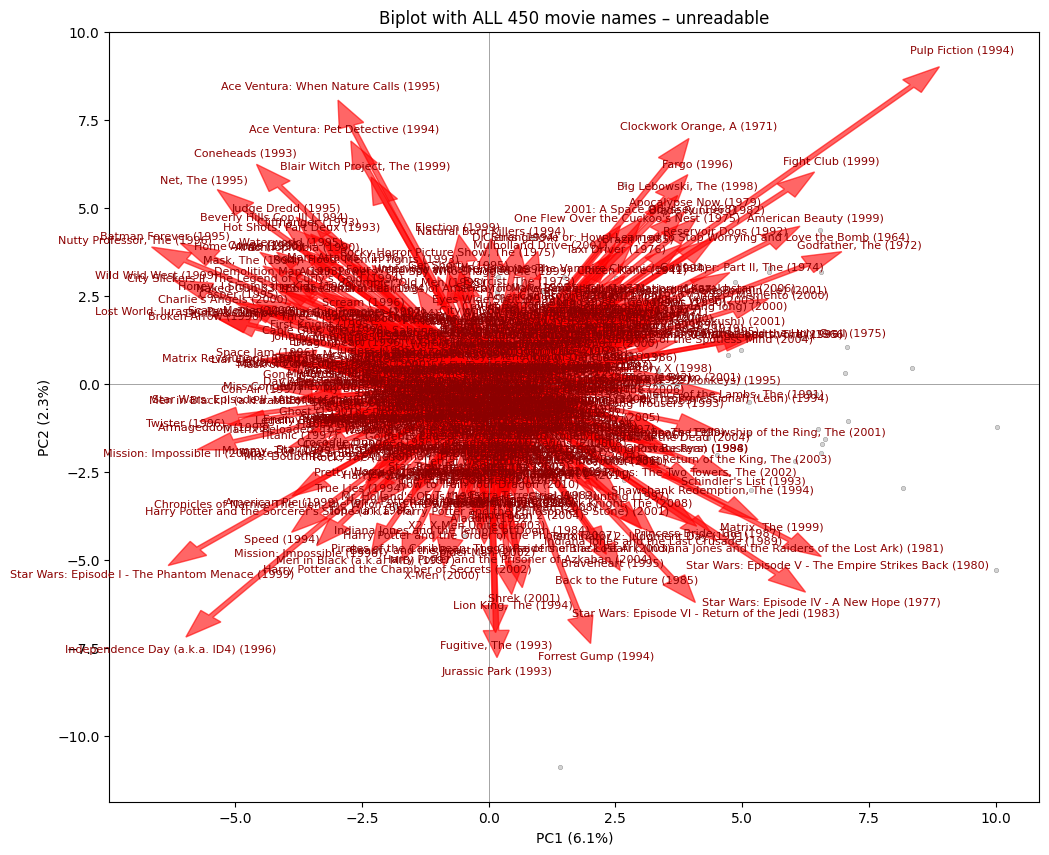

In [9]:
def biplot(scores, loadings, var_names, pcs=(0, 1), ax=None, label_idx=None, ratio=None):
    """Points = observations (scores), arrows = variables (loadings). label_idx = which arrows to draw."""
    if ax is None:
        fig, ax = plt.subplots(figsize=(11, 9))
    i, j = pcs
    xs, ys = scores[:, i], scores[:, j]
    ax.scatter(xs, ys, s=10, color="lightgrey", edgecolor="grey", linewidth=0.3)
    label_idx = np.arange(len(var_names)) if label_idx is None else np.asarray(label_idx)
    scale = 0.9 * min(np.abs(xs).max(), np.abs(ys).max()) / np.abs(loadings[label_idx][:, [i, j]]).max()
    for k in label_idx:
        dx, dy = loadings[k, i] * scale, loadings[k, j] * scale
        ax.arrow(0, 0, dx, dy, color="red", alpha=0.6, width=0.002 * scale, head_width=0.01 * scale, length_includes_head=True)
        ax.text(dx * 1.05, dy * 1.05, var_names[k], color="darkred", fontsize=8, ha="center", va="center")
    ax.axhline(0, color="grey", lw=0.5); ax.axvline(0, color="grey", lw=0.5)
    if ratio is not None:
        ax.set_xlabel(f"PC{i+1} ({ratio[i]:.1%})"); ax.set_ylabel(f"PC{j+1} ({ratio[j]:.1%})")
    return ax

load_pop = pca_pop.components_.T          # rows = movies, columns = PCs
fig, ax = plt.subplots(figsize=(12, 10))
biplot(scores_pop, load_pop, titles_pop, ax=ax, ratio=ratio_pop)
ax.set_title("Biplot with ALL 450 movie names – unreadable")
plt.show()

With 450 arrows and labels the plot is a red blob – **nothing can be read**. So we only draw the movies that matter most for
the first two PCs, i.e. the ones with the **longest arrows** (length √(loading₁² + loading₂²)).

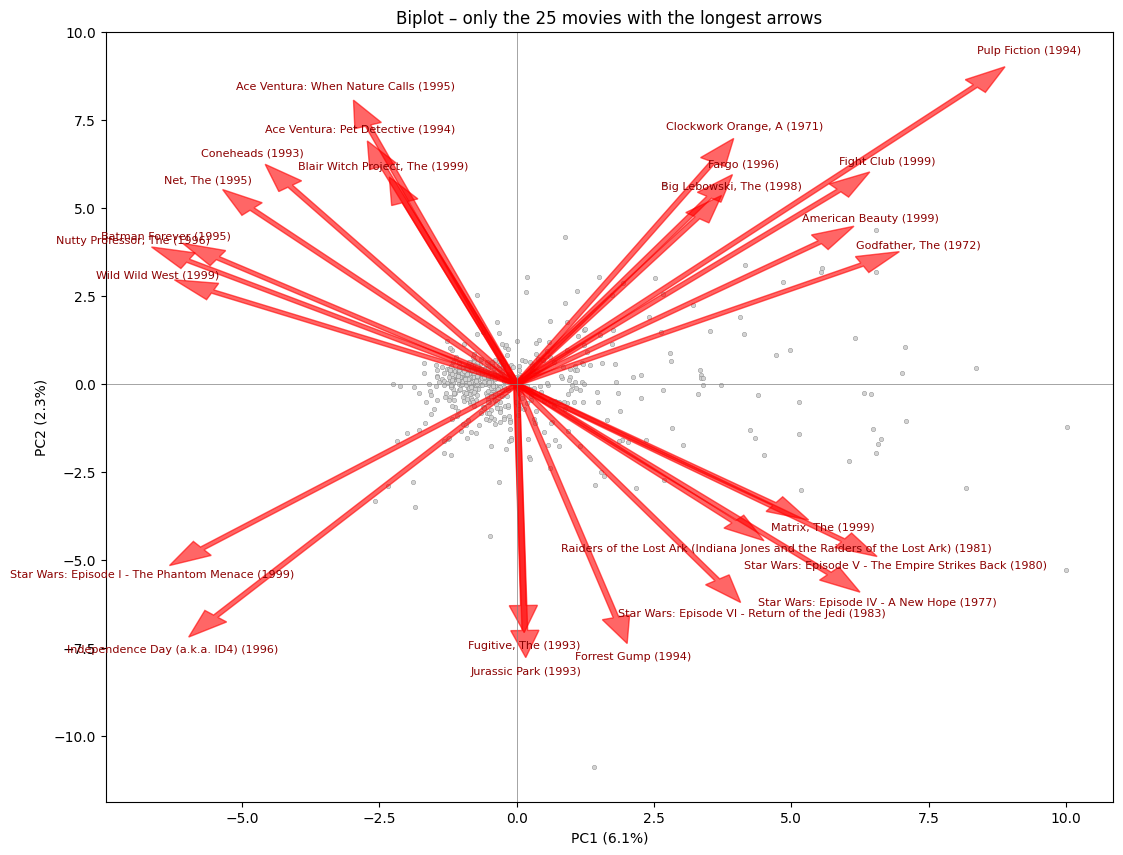

In [10]:
length = np.sqrt(load_pop[:, 0]**2 + load_pop[:, 1]**2)
top = np.argsort(length)[-25:]

fig, ax = plt.subplots(figsize=(13, 10))
biplot(scores_pop, load_pop, titles_pop, ax=ax, label_idx=top, ratio=ratio_pop)
ax.set_title("Biplot – only the 25 movies with the longest arrows")
plt.show()

To understand the two axes, we list the movies with the largest positive and negative coefficients on PC1 and PC2:

In [11]:
for k in range(2):
    L = pd.Series(load_pop[:, k], index=titles_pop)
    print(f"===== PC{k+1}: largest positive coefficients")
    print(L.nlargest(8).round(3).to_string())
    print(f"----- PC{k+1}: largest negative coefficients")
    print(L.nsmallest(8).round(3).to_string(), "\n")

===== PC1: largest positive coefficients
Pulp Fiction (1994)                                      0.173
Godfather, The (1972)                                    0.136
Star Wars: Episode V - The Empire Strikes Back (1980)    0.128
Fight Club (1999)                                        0.125
Star Wars: Episode IV - A New Hope (1977)                0.122
American Beauty (1999)                                   0.119
Memento (2000)                                           0.107
Monty Python and the Holy Grail (1975)                   0.105
----- PC1: largest negative coefficients
Nutty Professor, The (1996)                        -0.129
Star Wars: Episode I - The Phantom Menace (1999)   -0.123
Wild Wild West (1999)                              -0.121
Batman Forever (1995)                              -0.118
Independence Day (a.k.a. ID4) (1996)               -0.116
Mission: Impossible II (2000)                      -0.112
Twister (1996)                                     -0.111
Lost Wor

We check the meaning of PC1 by comparing its coefficients with the average rating of each movie (over the users who rated it):

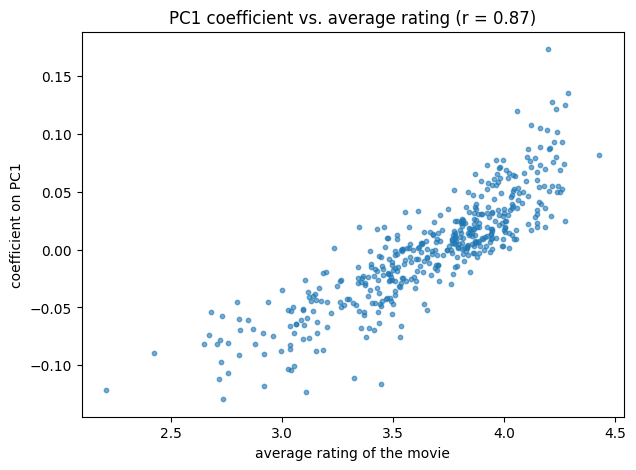

In [12]:
avg_rating = R_pop.mean().values
r_pc1 = np.corrcoef(avg_rating, load_pop[:, 0])[0, 1]
plt.figure(figsize=(7, 5))
plt.scatter(avg_rating, load_pop[:, 0], s=10, alpha=0.6)
plt.xlabel("average rating of the movie"); plt.ylabel("coefficient on PC1")
plt.title(f"PC1 coefficient vs. average rating (r = {r_pc1:.2f})")
plt.show()

Finally, in the biplot most users sit in a dense cloud near the origin and only a few lie far out. Does a user's position
depend on *how many* movies they rated?

correlation (distance from origin, number of rated movies): 0.78


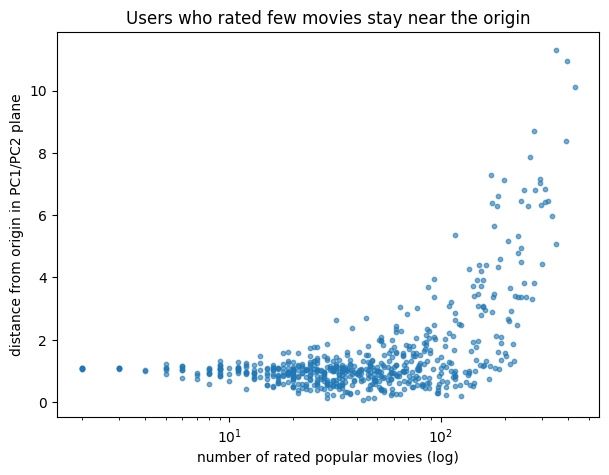

In [13]:
dist = np.sqrt(scores_pop[:, 0]**2 + scores_pop[:, 1]**2)      # distance of each user from the origin
n_rated = R_pop.notna().sum(axis=1).values
print(f"correlation (distance from origin, number of rated movies): {np.corrcoef(dist, n_rated)[0, 1]:.2f}")

plt.figure(figsize=(7, 5))
plt.scatter(n_rated, dist, s=10, alpha=0.6)
plt.xscale("log")
plt.xlabel("number of rated popular movies (log)"); plt.ylabel("distance from origin in PC1/PC2 plane")
plt.title("Users who rated few movies stay near the origin")
plt.show()

### What do we see?

**PC1 (≈ 6 %) – "acclaimed classics vs. weak blockbusters" (a quality axis)**
- Positive coefficients: *Pulp Fiction, The Godfather, Star Wars IV/V, Fight Club, American Beauty, Memento* – highly rated,
  critically acclaimed films.
- Negative coefficients: *The Nutty Professor, Star Wars Episode I, Wild Wild West, Batman Forever, Independence Day,
  Mission: Impossible II* – popular but rather weak blockbusters.
- The PC1 coefficients correlate strongly with the average rating of a movie (**r ≈ 0.87**). A user with a high PC1 score rates the
  "good" movies above their own average and the weak ones below it – they agree with the general opinion and differ a lot between good
  and bad films. Users with negative scores rate the weak blockbusters relatively better.

**PC2 (≈ 2 %) – "edgy / cult vs. mainstream crowd-pleasers" (a taste axis)**
- Positive: *Pulp Fiction, A Clockwork Orange, Fargo, The Big Lebowski, Fight Club, Blair Witch Project*, but also silly comedies like
  *Ace Ventura* and *Coneheads* – unusual, polarizing films.
- Negative: *Jurassic Park, Forrest Gump, The Fugitive, Star Wars VI, The Lion King, Shrek* – big mainstream and family hits that
  almost everybody likes.

Together the four quadrants of the biplot are quite readable:
- upper right – acclaimed edgy films (*Pulp Fiction, Fargo, Clockwork Orange*),
- lower right – acclaimed mainstream films (*Star Wars IV/V, The Matrix, Raiders of the Lost Ark*),
- upper left – weak silly comedies (*Ace Ventura, Coneheads, Nutty Professor*),
- lower left – weak mainstream blockbusters (*Star Wars I, Independence Day*).

**The users (points):** most users form a dense cloud around the origin, and only a few lie far out. The distance from the origin
correlates with the **number of rated movies (r ≈ 0.78)**: users with few ratings are mostly "0" (= filled-in missing values) and
therefore stay in the centre. So the position of a user in the plot partly shows *how much they rated*, not only *what they like*.

### How useful is this plot?

**The movie arrows give an interesting first impression, but overall the plot is of limited use – as expected from (b):**
1. **Too little information:** PC1 + PC2 explain only about **8 %** of the variance (we would need ≈ 180 – 250 dimensions for 90 %).
   More than 90 % of the differences between users are not visible. Two users that are close in the plot can have very different tastes.
2. **Too many variables:** with 450 (or 9 724) movies the standard biplot with all names is unreadable. We have to pick a few
   arrows ourselves (here the 25 longest), and all other movies are hidden.
3. **No clear structure in the users:** the user cloud has no visible groups. PC2 is not much more important than PC3, PC4, …
   (all ≈ 2 %), so the choice of exactly these two axes is somewhat arbitrary.
4. **Missing values:** about 85 % of the matrix (popular movies) is filled in by us. This pulls users with few ratings to the centre
   and mixes "how many movies a user rated" into the picture.

Compare with PC1 (superheroes): there 2 PCs explained 57 % of only 7 variables, so the biplot was readable and meaningful.
A biplot is useful when **few PCs explain most of the variance** and the number of variables is small – both conditions fail for the
movie data. For the movie data, PCA (or a related matrix factorization) is more useful as a compression step inside a recommender
system than as a visualization.

## Summary

| Question | Answer |
|---|---|
| (a) Data | User × movie rating matrix: 610 users × 9 724 movies, ratings 0.5 – 5 stars, **98.3 % missing**. No standardization (same scale and meaning), but each user is centered by their mean rating and missing values are set to 0 (= "average for this user"). |
| (b) Dimensions | PC1 ≈ 5 – 6 %, PC1+PC2 ≈ 8 %. 90 % needs ≈ 250 PCs (≈ 180 for the 450 popular movies); at most 609 PCs exist because there are only 610 users. No strong reduction is possible. |
| (c) Biplot | Unreadable with all names; with the top 25 movies PC1 can be read as "acclaimed classics vs. weak blockbusters", PC2 is unclear. The plot is of **limited use**, because 2 PCs show only ≈ 8 % of the information. |